# 02 · Multicopy teleportation — Fig. 2

Paper section *Multicopy teleportation on real hardware*.
Hardware runs are replaced by the `FakeKingston` noisy simulator.

* **(a) $m=1$** – teleport $\lvert+\rangle$ with $k=1\dots5$ copies, QSD and isometry decompositions.
* **(b) $m=2$** – two-qubit programs stored on Bob's qubits and retrieved on a product input:
  Bell on $\lvert00\rangle$, W on $\lvert00\rangle$, SWAP on $\lvert01\rangle$ ($k=1\dots4$, isometry).
  The ideal success probability is $p(2,k)^2$ because the two blocks herald independently.

Runtime: about 1 min for (a) and 5 min for (b) on a laptop (the $k=4$, $m=2$ circuits simulate 12 qubits).

In [1]:
# Load the shared settings and functions (00_core.ipynb must be in the same folder)
%run ./00_core.ipynb

FakeKingston: 156 qubits, native gates ['cz', 'delay', 'id', 'if_else', 'measure', 'measure_2', 'reset', 'rz', 'sx', 'x']
core loaded


## (a) Single-qubit teleportation

In [2]:
IN_STATE = "+"                                   # input of Fig. 2a
res_1q = {}
print(f"{'k':>2} {'method':<9} | {'p ideal':>8} {'F ideal':>8} | {'p noisy':>15} {'F noisy':>15}")
print("-" * 70)
for k in KS:
    for method in METHODS:
        for mode in ("ideal", "noisy"):
            res_1q[(k, method, mode)] = run_single_qubit(k, method, mode, in_state=IN_STATE)
        i, n = res_1q[(k, method, "ideal")], res_1q[(k, method, "noisy")]
        print(f"{k:>2} {method:<9} | {i['p']:>8.4f} {i['F']:>8.4f} | "
              f"{n['p']:.4f} ± {n['p_err']:.4f} {n['F']:.4f} ± {n['F_err']:.4f}")

 k method    |  p ideal  F ideal |         p noisy         F noisy
----------------------------------------------------------------------
 1 qsd       |   0.2511   0.9999 | 0.2525 ± 0.0025 0.9324 ± 0.0050
 1 isometry  |   0.2516   1.0000 | 0.2499 ± 0.0025 0.9240 ± 0.0052
 2 qsd       |   0.3364   1.0000 | 0.3251 ± 0.0027 0.9069 ± 0.0051
 2 isometry  |   0.3323   0.9999 | 0.3286 ± 0.0027 0.9078 ± 0.0050
 3 qsd       |   0.3778   0.9998 | 0.3021 ± 0.0027 0.8510 ± 0.0065
 3 isometry  |   0.3726   0.9999 | 0.3379 ± 0.0027 0.8879 ± 0.0054
 4 qsd       |   0.4029   0.9999 | 0.1538 ± 0.0021 0.6244 ± 0.0125
 4 isometry  |   0.3987   0.9997 | 0.2795 ± 0.0026 0.8436 ± 0.0068
 5 qsd       |   0.4157   0.9999 | 0.0790 ± 0.0016 0.5113 ± 0.0183
 5 isometry  |   0.4210   1.0000 | 0.1171 ± 0.0019 0.6525 ± 0.0138


## (b) Two-qubit program retrieval

In [3]:
KS_2Q = (1, 2, 3, 4)
PROGRAMS_2Q = {"Bell": ("0", "0"), "W": ("0", "0"), "SWAP": ("0", "1")}   # program: input |q1 q2>
METHOD_2Q = "isometry"

res_2q = {}
print(f"{'k':>2} {'program':<5} | {'p(2,k)^2':>8} | {'p ideal':>8} {'F ideal':>8} | {'p noisy':>15} {'F noisy':>15}")
print("-" * 80)
for k in KS_2Q:
    for prog, inputs in PROGRAMS_2Q.items():
        for mode in ("ideal", "noisy"):
            res_2q[(k, prog, mode)] = run_two_qubit(k, METHOD_2Q, mode, prog, inputs)
        i, n = res_2q[(k, prog, "ideal")], res_2q[(k, prog, "noisy")]
        print(f"{k:>2} {prog:<5} | {p_theory(k)**2:>8.4f} | {i['p']:>8.4f} {i['F']:>8.4f} | "
              f"{n['p']:.4f} ± {n['p_err']:.4f} {n['F']:.4f} ± {n['F_err']:.4f}")

 k program | p(2,k)^2 |  p ideal  F ideal |         p noisy         F noisy
--------------------------------------------------------------------------------
 1 Bell  |   0.0625 |   0.0601   1.0000 | 0.0676 ± 0.0025 0.9320 ± 0.0097
 1 W     |   0.0625 |   0.0638   1.0000 | 0.0636 ± 0.0024 0.9151 ± 0.0111
 1 SWAP  |   0.0625 |   0.0672   1.0000 | 0.0651 ± 0.0025 0.9109 ± 0.0112
 2 Bell  |   0.1111 |   0.1030   1.0000 | 0.1066 ± 0.0031 0.8837 ± 0.0098
 2 W     |   0.1111 |   0.1160   1.0000 | 0.1063 ± 0.0031 0.8975 ± 0.0093
 2 SWAP  |   0.1111 |   0.1156   1.0000 | 0.1063 ± 0.0031 0.8928 ± 0.0095
 3 Bell  |   0.1406 |   0.1421   1.0000 | 0.1109 ± 0.0031 0.8476 ± 0.0108
 3 W     |   0.1406 |   0.1364   1.0000 | 0.1133 ± 0.0032 0.8350 ± 0.0110
 3 SWAP  |   0.1406 |   0.1405   1.0000 | 0.1121 ± 0.0032 0.8376 ± 0.0110
 4 Bell  |   0.1600 |   0.1552   1.0000 | 0.0718 ± 0.0026 0.7117 ± 0.0169
 4 W     |   0.1600 |   0.1634   1.0000 | 0.0700 ± 0.0026 0.6743 ± 0.0177
 4 SWAP  |   0.1600 |   0.164

## Figure 2

Dashed lines: ideal success probability. Grey regions: below the single-copy rates $1/4$ and $1/16$.
Filled markers: `FakeKingston` simulation; faint crosses: ideal `AerSimulator`.

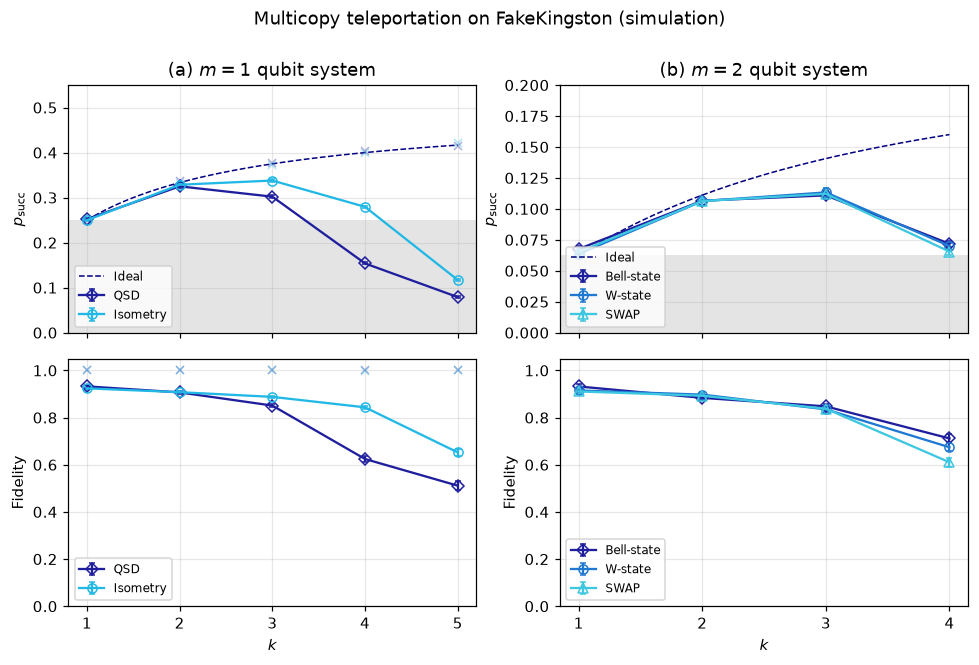

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(9, 6), sharex="col")
k_fine = np.linspace(1, max(KS), 100)

# ---- (a) m = 1 ---------------------------------------------------------------
ax[0, 0].plot(k_fine, p_theory(k_fine), "--", color="navy", lw=1, label="Ideal")
ax[0, 0].axhspan(0, 0.25, color="lightgrey", alpha=0.6, lw=0)
for method, st in METHOD_STYLE.items():
    for row, key in ((0, "p"), (1, "F")):
        y = [res_1q[(k, method, "noisy")][key] for k in KS]
        e = [res_1q[(k, method, "noisy")][key + "_err"] for k in KS]
        ax[row, 0].errorbar(KS, y, e, color=st["color"], marker=st["marker"], mfc="none",
                            capsize=2, label=st["label"])
        ax[row, 0].plot(KS, [res_1q[(k, method, "ideal")][key] for k in KS], "x",
                        color=st["color"], alpha=0.35, ms=5)
ax[0, 0].set(title="(a) $m=1$ qubit system", ylabel=r"$p_{\rm succ}$", ylim=(0, 0.55))
ax[1, 0].set(xlabel="$k$", ylabel="Fidelity", ylim=(0, 1.05), xticks=KS)

# ---- (b) m = 2 ---------------------------------------------------------------
k_fine2 = np.linspace(1, max(KS_2Q), 100)
ax[0, 1].plot(k_fine2, p_theory(k_fine2) ** 2, "--", color="navy", lw=1, label="Ideal")
ax[0, 1].axhspan(0, 1 / 16, color="lightgrey", alpha=0.6, lw=0)
colors_2q = {"Bell": "#1f1f9e", "W": "#1f78d1", "SWAP": "#3ec7e0"}
markers_2q = {"Bell": "D", "W": "o", "SWAP": "^"}
for prog in PROGRAMS_2Q:
    for row, key in ((0, "p"), (1, "F")):
        y = [res_2q[(k, prog, "noisy")][key] for k in KS_2Q]
        e = [res_2q[(k, prog, "noisy")][key + "_err"] for k in KS_2Q]
        ax[row, 1].errorbar(KS_2Q, y, e, color=colors_2q[prog], marker=markers_2q[prog],
                            mfc="none", capsize=2, label=f"{prog}-state" if prog != "SWAP" else "SWAP")
ax[0, 1].set(title="(b) $m=2$ qubit system", ylabel=r"$p_{\rm succ}$", ylim=(0, 0.2))
ax[1, 1].set(xlabel="$k$", ylabel="Fidelity", ylim=(0, 1.05), xticks=KS_2Q)

for a in ax.flat:
    a.legend(loc="lower left")
fig.suptitle("Multicopy teleportation on FakeKingston (simulation)", y=1.0)
fig.tight_layout()
plt.show()